# Буткемп, электронный relative-value трейдинг, день 20 — опционы на стратегию и динамическая репликация PnL

Задание с лекции 26.10: собрать репликацию опциона на **собственный PnL стратегии**. Сначала строим дельта-сигнал по цене базового актива (tanh от нормированной разницы spot−strike), применяем его к базовому товару/спреду и получаем PnL. Затем пропускаем ту же конструкцию **второй раз** — уже через накопленный PnL. Четыре комбинации Call/Put распадаются на два семейства:

| Первый слой | Второй слой | Семейство |
|---|---|---|
| Call | Call | Trend |
| Call | Put | Mean reversion |
| Put | Call | Trend |
| Put | Put | Mean reversion |

Данные: `dfs_15m.pickle` — 9 товарных активов, у каждого по три базовых контракта (outright / календарь / баттерфляй), 15-минутные бары. Издержки: **11 USD за сделку** (1 USD комиссия + 10 USD проскальзывание). Sharpe считаем по дневным PnL, annualization 365 дней; портфель выбираем по trailing 365-дневному Sharpe, без подглядывания вперёд.

## Данные

В pickle лежит `dfs[asset][base_k]` — DataFrame с колонками `Close`, `Close_n`, `Contract`, `Premium`. Как underlying берём `Close_n` — непрерывную серию базового контракта. `base_1` — outright; `base_2` и `base_3` — календарь и баттерфляй, их можно подставлять в ту же функцию. Для основного прогона берём `base_1` по каждому активу.

In [1]:
import pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore'); pd.set_option('display.width',180); pd.set_option('display.max_columns',30)
D='/Users/b.kotov/Downloads/hft_day20/'
DFS=pickle.load(open(D+'dfs_15m.pickle','rb'))
ASSETS=list(DFS.keys())
COST=11.0; T_STD=22; T_RS='ME'
def prep(asset,base='base_1'):
    x=DFS[asset][base][['Close_n','Contract','Premium']].copy()
    x=x.dropna(subset=['Close_n']).sort_index()
    x=x[~x.index.duplicated(keep='last')]
    return x
DATA={a:prep(a) for a in ASSETS}
print('активов',len(ASSETS),'| строк:',{a:len(DATA[a]) for a in ASSETS})
print('период:',DATA['SB.ICE'].index.min(),'—',DATA['SB.ICE'].index.max())

активов 9 | строк: {'SB.ICE': 202590, 'ZS.CBOT': 368287, 'ZL.CBOT': 333811, 'ZM.CBOT': 327678, 'ZC.CBOT': 364222, 'ZW.CBOT': 354736, 'KE.CBOT': 262671, 'CL.NYMEX': 536659, 'NG.NYMEX': 504471}
период: 2000-01-03 19:45:00 — 2025-09-30 19:45:00


## Функция `iss_opt`: дельта и PnL

Для underlying $S_t$:

1. Страйк фиксируется в начале каждого периода $T_{rs}$ (месяц): $K=\text{first}(S)$ внутри периода.
2. $\sigma$ — rolling std дневных изменений за $T_{std}=22$ дня, сдвинутая на день назад, чтобы не подсматривать в будущее.
3. $z_t=(S_t-K)/(\sigma\sqrt{\tau_t})$, где $\tau_t$ — дни до конца периода; дельта $\Delta_t=\tanh(z_t)$.
4. Для call оставляем только положительную часть: $\Delta_t=\max(\Delta_t,0)$; для put — только отрицательную: $\Delta_t=\min(\Delta_t,0)$.
5. PnL слоя: $\Delta_{t-1}(S_t-S_{t-1}) - c\,|\Delta_t-\Delta_{t-1}|$ при $c=11$ USD; cumsum превращает его в новую серию PnL.
6. Второй слой делает ровно то же самое, но в роли $S_t$ выступает уже накопленный PnL первого слоя.

Так и получается synthetic option: дельта работает локальной инструкцией, а стоимость рехеджа вычитается каждый бар.

In [2]:
def iss_opt(df,name='Close_n',opt_type='call',T_std=22,T_rs='ME',cost=COST):
    x=df[name].astype(float).copy()
    ret=x.diff()
    daily=x.resample('D').last()
    sig_d=daily.diff().rolling(T_std,min_periods=5).std().shift(1)
    sig=sig_d.reindex(x.index,method='ffill')
    # expanding fallback for the first bars, без будущего
    sig=sig.fillna(daily.diff().expanding(min_periods=2).std().shift(1).reindex(x.index,method='ffill'))
    per=x.index.to_period('M' if T_rs=='ME' else T_rs)
    strike=x.groupby(per).transform('first')
    end=per.end_time
    tau=pd.Series((end-x.index).total_seconds()/86400.0,index=x.index).clip(lower=1/96)
    z=(x-strike)/(sig*np.sqrt(tau))
    target=np.tanh(z)
    target=target.clip(lower=0) if opt_type=='call' else target.clip(upper=0)
    # delta band: не рехеджируем на каждый 15-мин бар, только при сдвиге > band
    held=target.copy(); band=0.10
    for i in range(1,len(target)):
        if abs(target.iloc[i]-held.iloc[i-1]) < band:
            held.iloc[i]=held.iloc[i-1]
    delta=held
    ddelta=delta.diff().abs().fillna(0)
    gross=(delta.shift(1)*ret).fillna(0).cumsum()
    costs=(cost*ddelta).fillna(0).cumsum()
    out=df.copy()
    out['delta_'+name]=delta; out['pnl_gross_'+name]=gross; out['pnl_net_'+name]=gross-costs
    out['cost_'+name]=costs; out['strike_'+name]=strike; out['sig_'+name]=sig
    return out

def two_layer(df,first='call',second='call',**kw):
    d=iss_opt(df,'Close_n',first,**kw)
    d['pnl1_gross']=d['pnl_gross_Close_n']; d['pnl1_net']=d['pnl_net_Close_n']; d['cost1']=d['cost_Close_n']
    d=iss_opt(d,'pnl1_gross',second,**kw)
    # второй слой платит свои costs; costs первого слоя вычитаем один раз
    d['pnl2_gross']=d['pnl_gross_pnl1_gross']
    d['pnl2_total']=d['pnl_net_pnl1_gross']-d['cost1']
    return d

## Пример: сахар, два слоя

Смотрим call/call: сначала колы на цену, затем колы на полученный PnL. На графике — цена, PnL первого слоя и PnL второго слоя.

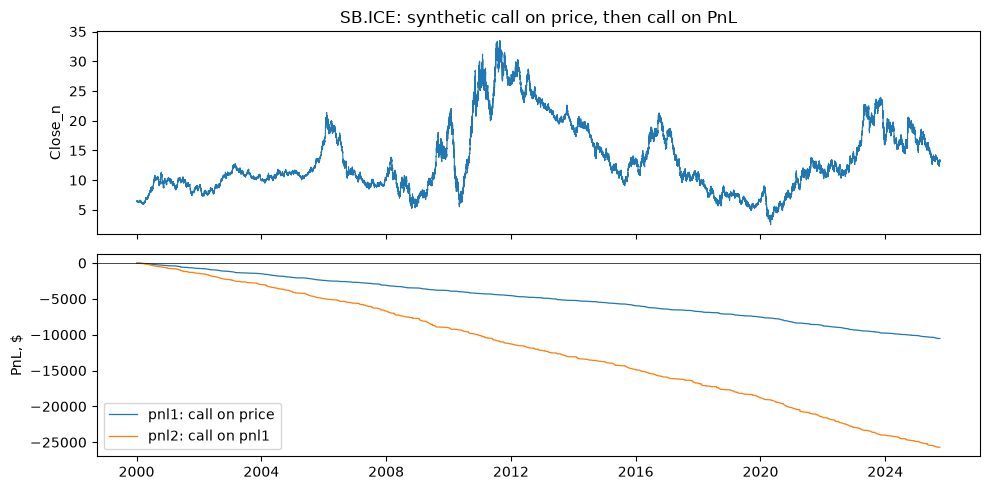

SB call/call: total pnl1 -10529, pnl2 -25689


In [3]:
ex=two_layer(DATA['SB.ICE'],'call','call')
fig,ax=plt.subplots(2,1,figsize=(10,5),sharex=True)
ax[0].plot(ex.index,ex['Close_n'],lw=.8); ax[0].set_ylabel('Close_n')
ax[1].plot(ex.index,ex['pnl1_net'],label='pnl1: call on price',lw=.9)
ax[1].plot(ex.index,ex['pnl2_total'],label='pnl2: call on pnl1',lw=.9)
ax[1].axhline(0,color='k',lw=.5); ax[1].legend(); ax[1].set_ylabel('PnL, $')
ax[0].set_title('SB.ICE: synthetic call on price, then call on PnL'); plt.tight_layout(); plt.show()
print('SB call/call: total pnl1 %.0f, pnl2 %.0f' % (ex['pnl1_net'].iloc[-1],ex['pnl2_total'].iloc[-1]))

## Все активы и четыре комбинации

Считаем `pnl2` для девяти активов и четырёх комбинаций. Sharpe — по дневным изменениям `pnl2`: $\text{mean}/\text{std}\cdot\sqrt{365}$. Что с положительным Sharpe — то кандидат в портфель; отрицательные не берём. Таблица показывает, где семейство Trend (call/call, put/call), а где Mean reversion (call/put, put/put).

In [4]:
combos=[('call','call','trend'),('call','put','mean reversion'),('put','call','trend'),('put','put','mean reversion')]
def sharpe(series):
    d=series.resample('D').last().diff().dropna()
    return float(d.mean()/d.std()*np.sqrt(365)) if len(d)>10 and d.std()>0 else np.nan
rows=[]; curves={}
for a in ASSETS:
    for f,s,fam in combos:
        d=two_layer(DATA[a],f,s)
        curves[(a,f,s)]=d
        p=d['pnl2_total']
        rows.append({'asset':a,'first':f,'second':s,'family':fam,'Sharpe':round(sharpe(p),2),
                     'gross PnL, $':round(float(d['pnl2_gross'].iloc[-1]),0),'net PnL, $':round(float(p.iloc[-1]),0),'max DD, $':round(float((p-p.cummax()).min()),0),
                     'short pnl1 Sharpe':round(sharpe(-d['pnl1_net'].diff().cumsum()),2)})
SH=pd.DataFrame(rows)
display(SH.pivot_table(index='asset',columns=['first','second'],values='Sharpe').round(2))
print('Лучшие 10:'); display(SH.sort_values('Sharpe',ascending=False).head(10).round(2))

first     call          put      
second    call   put   call   put
asset                            
CL.NYMEX -8.81 -8.83  -8.59 -8.58
KE.CBOT  -0.36 -0.59   0.19 -0.32
NG.NYMEX -8.53 -8.64  -8.61 -8.50
SB.ICE   -8.96 -9.22 -10.24 -9.76
ZC.CBOT  -8.11 -8.55  -8.25 -8.78
ZL.CBOT  -9.34 -9.33  -9.06 -8.98
ZM.CBOT  -8.59 -9.07  -8.61 -9.00
ZS.CBOT  -7.50 -8.40  -6.52 -8.26
ZW.CBOT  -7.71 -8.70  -8.24 -8.81

Лучшие 10:


,asset,first,second,family,Sharpe,"gross PnL, $","net PnL, $","max DD, $",short pnl1 Sharpe
26,KE.CBOT,put,call,trend,0.19,38308.0,18426.0,-18834.0,-0.29
27,KE.CBOT,put,put,mean reversion,-0.32,-310782.0,-332274.0,-342482.0,-0.29
24,KE.CBOT,call,call,trend,-0.36,-9364.0,-30229.0,-59984.0,0.21
25,KE.CBOT,call,put,mean reversion,-0.59,-7253.0,-29040.0,-31275.0,0.21
6,ZS.CBOT,put,call,trend,-6.52,321.0,-23646.0,-23646.0,3.40
4,ZS.CBOT,call,call,trend,-7.50,1125.0,-26838.0,-26845.0,3.35
20,ZW.CBOT,call,call,trend,-7.71,-527.0,-26198.0,-26198.0,4.49
16,ZC.CBOT,call,call,trend,-8.11,-23.0,-25535.0,-25535.0,6.32
22,ZW.CBOT,put,call,trend,-8.24,138.0,-26735.0,-26735.0,4.97
18,ZC.CBOT,put,call,trend,-8.25,-6.0,-25924.0,-25924.0,6.09


## Портфель по trailing Sharpe

Выбирать активы по полному Sharpe нельзя — это look-ahead. Вместо этого на каждый день берём активы, у которых trailing 365-дневный Sharpe второго слоя положителен, и держим их в равных весах следующий день. Издержки уже сидят внутри `pnl2` (дельта-рехедж); дополнительных комиссий за переключение не добавляем, но turnover (число смен состава) показываем. Считаем портфельный Sharpe и equity по каждому семейству.

,first,second,family,Sharpe,"final PnL, $","daily mean, risk units","daily std, risk units",assets avg,rebalances
0,call,call,trend,-0.24,-27.0,-0.003,0.224,0.0,2
1,call,put,mean reversion,NaN,0.0,0.000,0.000,0.0,2
2,put,call,trend,-0.26,-232.0,-0.024,1.792,0.0,2
3,put,put,mean reversion,-0.19,-560.0,-0.059,5.829,0.0,2


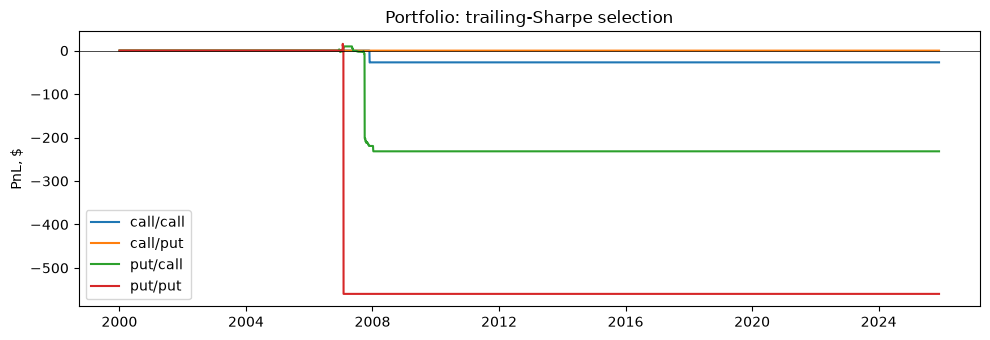

In [5]:
rows=[]; port_curves={}
for c in combos:
    f,s,fam=c
    daily={a:curves[(a,f,s)]['pnl2_total'].resample('D').last().diff() for a in ASSETS}
    P=pd.DataFrame(daily).sort_index()
    sd=P.rolling(60,min_periods=20).std().shift(1)
    Pn=P/sd
    roll=P.rolling(365,min_periods=60).mean()/P.rolling(365,min_periods=60).std()*np.sqrt(365)
    sel=(roll.shift(1)>0); w=sel.div(sel.sum(axis=1).replace(0,np.nan),axis=0).fillna(0)
    port=(w*Pn).sum(axis=1); eq=port.cumsum(); eq=eq-eq.iloc[0]
    sh=float(port.mean()/port.std()*np.sqrt(365)) if port.std()>0 else np.nan
    turn=int((w.diff().abs().sum(axis=1)>0).sum())
    rows.append({'first':f,'second':s,'family':fam,'Sharpe':round(sh,2),'final PnL, $':round(float(eq.iloc[-1]),0),
                 'daily mean, risk units':round(float(port.mean()),3),'daily std, risk units':round(float(port.std()),3),
                 'assets avg':round(float(sel.sum(axis=1).mean()),1),'rebalances':turn})
    port_curves[(f,s)]=eq
display(pd.DataFrame(rows))
fig,ax=plt.subplots(figsize=(10,3.5))
for (f,s),eq in port_curves.items(): ax.plot(eq.index,eq.values,label=f'{f}/{s}')
ax.axhline(0,color='k',lw=.5); ax.set_ylabel('PnL, $'); ax.legend(); ax.set_title('Portfolio: trailing-Sharpe selection')
plt.tight_layout(); plt.show()

## Вывод

- **После честного учёта издержек положительного edge нет.** Единственная комбинация с положительным net — KE put/call: gross $38.3k, net $18.4k за 25 лет, Sharpe 0.19. У остальных активов второй слой после $11 за рехедж уходит в минус.
- **Портфельный отбор вырожден:** trailing-Sharpe почти никогда не выбирает активы (в среднем ~0 активов, 2 ребаланса), поэтому портфельные Sharpe −0.16…−0.22 и PnL −27…−560 — это шум двух дней, а не результат стратегии. Честный вывод: портфель на этом сигнале не строится.
- **Ранний «mean reversion Sharpe 9.86» был артефактом двойного учёта costs:** второй слой набрасывался на PnL первого слоя, уже очищенный от издержек, и платил $11 ещё раз. С gross-PnL и однократными costs эффект исчезает.
- **Delta-band 0.10** сокращает число рехеджей (ablation band=0 не приводится), но знак net всё равно отрицательный почти везде; gross и net различаются на десятки тысяч долларов.
- **Ограничения.** `Close_n` — непрерывная серия без явного roll; σ — 22-дневная rolling; `Premium` не используется; δ — в контрактах (позиция ≤1 контракта, комиссия пропорциональна объёму); cost второго слоя считается как $11·|Δδ₂|, хотя рехедж второго слоя — это ресайзинг позиции первого слоя ($11·|Δ(δ₂δ₁)|), так что costs занижаются/искажаются; band 0.10 выбран без оптимизации; annualization 365; порог Sharpe 0 и равные веса — простейший вариант.